# ML Foundations

A concise reference covering the mathematical framework of supervised learning: problem formalization, loss functions, empirical risk minimization, evaluation protocols, metrics, and feature scaling.

---

## Table of Contents

1. [Introduction & ML Taxonomy](#introduction)
2. [Loss Functions](#loss-functions)
3. [Bayes Error](#bayes-error)
4. [Minimize the Risk](#minimize-the-risk)
5. [Bias-Variance Decomposition](#decomposition)
6. [Empirical Risk & ERM](#empirical-risk)
7. [Guarantees & Limitations of ERM](#guarantees-and-limitations-of-erm)
8. [Bayes, Likelihood & Cross-Entropy](#bayes-likelihood-and-cross-entropy)
9. [KL Divergence](#kl-divergence)
10. [Evaluation Protocol](#evaluation-protocol)
11. [Evaluation Metrics — Classification](#classification-metrics)
12. [Evaluation Metrics — Regression](#regression-metrics)
13. [Feature Scaling](#feature-scaling)
14. [Practical Pipeline](#practical-pipeline)
15. [Sources](#sources)

<a id="introduction"></a>
## Introduction & ML Taxonomy

Machine learning is the study of algorithms that improve automatically through experience.

| Paradigm | Supervision | Goal |
|---|---|---|
| **Supervised** | Labels available | Learn $h: X \to Y$ from $(x_i, y_i)$ pairs |
| **Unsupervised** | No labels | Discover structure in $X$ |
| **Reinforcement** | Reward signal | Learn policy via environment interaction |

This notebook focuses on **supervised learning**.

### Classification vs Regression

| | Classification | Regression |
|---|---|---|
| Output space $Y$ | Discrete $\{c_1, \ldots, c_K\}$ | $\mathbb{R}$ (or $\mathbb{R}^d$) |
| Prediction | Class label | Real value |
| Canonical loss | 0-1, cross-entropy | MSE, MAE |
| Example | Spam detection | House price prediction |

**Binary classification**: $Y = \{0, 1\}$  
**Multiclass**: $Y = \{1, \ldots, K\}$  
**Multilabel**: $Y = \{0,1\}^K$ — multiple classes simultaneously

### The Learning Problem

Given a dataset $\mathcal{D} = \{(x_i, y_i)\}_{i=1}^n$ drawn i.i.d. from an unknown distribution $P(x,y)$, find a hypothesis $h \in \mathcal{H}$ that minimizes expected loss on unseen data.

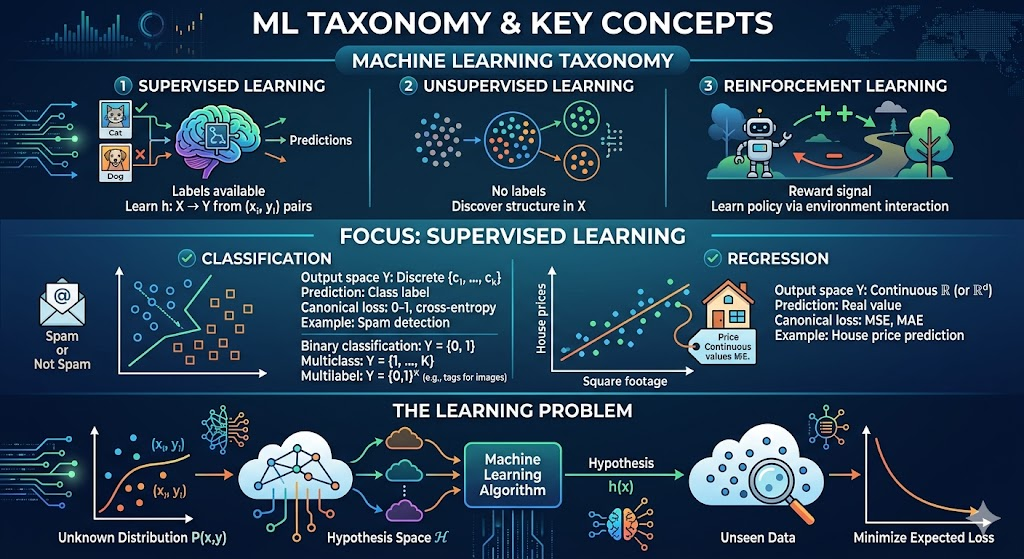

---

<a id="loss-functions"></a>
## Loss Functions

A loss function $L(\hat{y}, y)$ quantifies the cost of predicting $\hat{y}$ when the true value is $y$. The choice of loss shapes which errors the model penalizes.

### Classification Losses

**0-1 Loss** (theory only — non-convex, NP-hard to minimize directly):
$$L_{0\text{-}1}(\hat{y}, y) = \mathbf{1}[\hat{y} \neq y]$$

**Hinge Loss** (convex surrogate for 0-1, used in SVMs):
$$L_{\text{hinge}}(f(x), y) = \max(0,\; 1 - y \cdot f(x)), \quad y \in \{-1, +1\}$$

**Binary Cross-Entropy / Log Loss** (logistic regression, neural networks):
$$L_{\text{BCE}}(p, y) = -y \log p - (1-y) \log(1-p), \quad p = P_\theta(y=1 \mid x)$$

**Multiclass Cross-Entropy**:
$$L_{\text{CE}}(\mathbf{p}, y) = -\sum_{k=1}^{K} \mathbf{1}[y=k] \log p_k$$

### Regression Losses

**Mean Squared Error (MSE) / L2**:
$$L_{\text{MSE}}(\hat{y}, y) = (\hat{y} - y)^2$$

**Mean Absolute Error (MAE) / L1** (robust to outliers):
$$L_{\text{MAE}}(\hat{y}, y) = |\hat{y} - y|$$

**Huber Loss** (combines L1 and L2 — smooth near 0, linear in tails):
$$L_\delta(\hat{y}, y) = \begin{cases} \frac{1}{2}(\hat{y}-y)^2 & \text{if } |\hat{y}-y| \leq \delta \\ \delta \left(|\hat{y}-y| - \frac{\delta}{2}\right) & \text{otherwise} \end{cases}$$

| Loss | Convex | Differentiable | Robust to outliers |
|------|:------:|:--------------:|:-----------------:|
| 0-1 | No | No | Yes |
| Hinge | Yes | No (kink at 1) | No |
| Cross-entropy | Yes | Yes | No |
| MSE | Yes | Yes | No |
| MAE | Yes | No (kink at 0) | Yes |
| Huber | Yes | Yes | Yes |

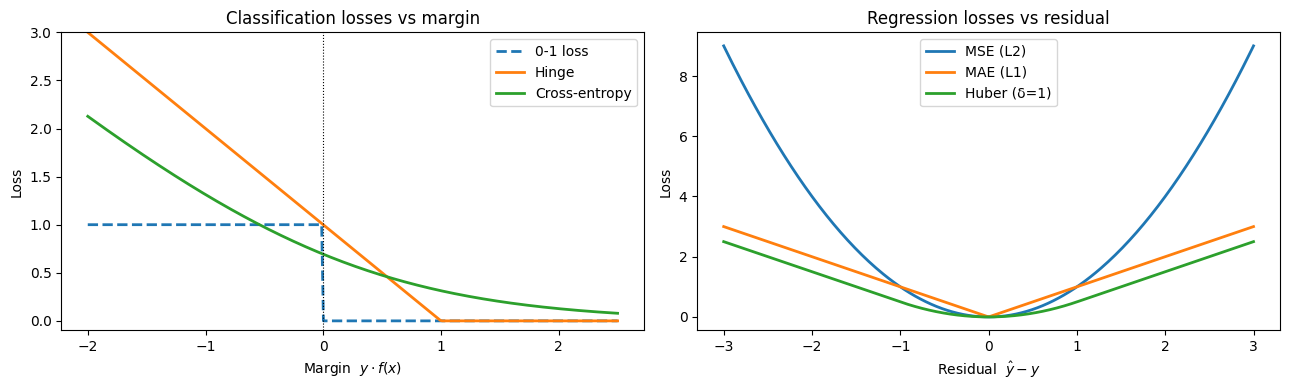

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Loss function implementations ---

def loss_01(y_hat, y):
    return (y_hat != y).astype(float)

def loss_hinge(fx, y):
    """fx: raw score f(x), y in {-1, +1}"""
    return np.maximum(0, 1 - y * fx)

def loss_bce(p, y):
    """p: predicted probability P(y=1|x), y in {0, 1}"""
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -y * np.log(p) - (1 - y) * np.log(1 - p)

def loss_mse(y_hat, y):
    return (y_hat - y) ** 2

def loss_mae(y_hat, y):
    return np.abs(y_hat - y)

def loss_huber(y_hat, y, delta=1.0):
    r = np.abs(y_hat - y)
    return np.where(r <= delta, 0.5 * r**2, delta * (r - 0.5 * delta))

# --- Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Classification: loss vs margin  m = y * f(x)
margin = np.linspace(-2, 2.5, 300)
ax = axes[0]
ax.plot(margin, (margin < 0).astype(float), label="0-1 loss", lw=2, ls='--')
ax.plot(margin, loss_hinge(margin, np.ones_like(margin)), label="Hinge", lw=2)
ax.plot(margin, loss_bce(1 / (1 + np.exp(-margin)), np.ones_like(margin)), label="Cross-entropy", lw=2)
ax.axvline(0, color='k', lw=0.8, ls=':')
ax.set_xlabel("Margin  $y \\cdot f(x)$"); ax.set_ylabel("Loss")
ax.set_title("Classification losses vs margin"); ax.legend(); ax.set_ylim(-0.1, 3)

# Regression: loss vs residual
r = np.linspace(-3, 3, 300)
ax = axes[1]
ax.plot(r, loss_mse(r, 0), label="MSE (L2)", lw=2)
ax.plot(r, loss_mae(r, 0), label="MAE (L1)", lw=2)
ax.plot(r, loss_huber(r, 0, delta=1.0), label="Huber (δ=1)", lw=2)
ax.set_xlabel("Residual  $\\hat{y} - y$"); ax.set_ylabel("Loss")
ax.set_title("Regression losses vs residual"); ax.legend()

plt.tight_layout()
plt.show()

## Bayes error

We compare model error with human error. Why? After an algorithm reaches the human level performance the progress and accuracy slow down. You won't surpass an error that's called "Bayes optimal error". There isn't much error range between human-level error and Bayes optimal error.
Humans are quite good at a lot of tasks. So as long as Machine learning is worse than humans, you can:
- Get labeled data from humans.
- Gain insight from manual error analysis: why did a person get it right?
- Better analysis of bias/variance.

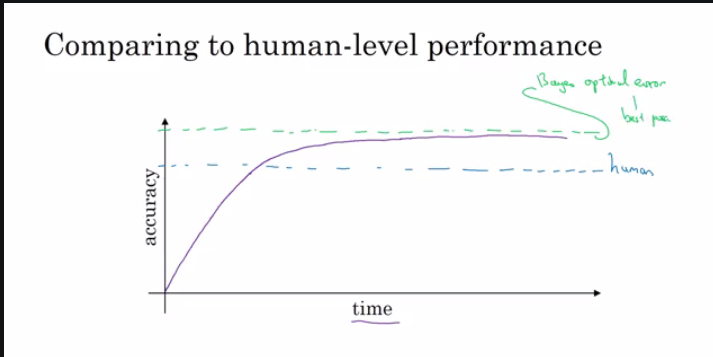

Suppose that the cat classification algorithm gives these results:

| Humans         | 1% | 7.5%  |
| Training error | 8% |  8%   |
|  Dev error     |10% | 10%   |

In the left example, because the human level error is 1% then we have to focus on the **bias**.
In the right example, because the human level error is 7.5% then we have to focus on the **variance**.
The human-level error as a proxy (estimate) for Bayes optimal error. Bayes optimal error is always less (better), but human-level in most cases is not far from it.

You can't do better than Bayes error unless you are overfitting.

- Avoidable bias = Training error - Human (Bayes) error
- Variance = Dev error - Training error

## Improving your model performance
The two fundamental asssumptions of supervised learning:
- You can fit the training set pretty well. This is roughly saying that you can achieve low avoidable bias.
- The training set performance generalizes pretty well to the dev/test set. This is roughly saying that variance is not too bad.

To improve your deep learning supervised system follow these guidelines:
- Look at the difference between human level error and the training error - avoidable bias. If avoidable bias is large you have these options:
    - Train bigger model.
    - Train longer/better optimization algorithm (like Momentum, RMSprop, Adam).
    - Find better NN architecture/hyperparameters search.
- Look at the difference between the dev/test set and training set error - Variance. If variance is large you have these options:
    - Get more training data.
    - Regularization (L2, Dropout, data augmentation).
    - Find better NN architecture/hyperparameters search.

---

## Minimize the risk

In machine learning, the goal is to find a function $f(x)$ that makes as few prediction errors as possible, i.e. to minimize a “risk” (the expected error).

### True risk

We consider two spaces:
- Input space: $X$
- Output space: $Y$

The goal is to learn a function (hypothesis): $$h : X \to Y$$ which maps an input $x \in X$ to an output $y \in Y$. We are given a training set of $n$ examples:
$$
(x_1, y_1), \ldots, (x_n, y_n)
$$
where:
- $x_i \in X$ is an input
- $y_i \in Y$ is the corresponding desired output for $h(x_i)$

We assume the existence of a joint probability distribution:
$$
P(x, y)
$$
over $X \times Y$, and that the training samples are drawn **i.i.d.** from this distribution.

We introduce a non-negative loss function:
$$
L(\hat{y}, y)
$$
which measures how different the prediction $\hat{y} = h(x)$ is from the true output $y$.

A commonly used loss function in theory is the **0-1 loss**:

$$
L(\hat{y}, y) =
\begin{cases}
1 & \text{if } \hat{y} \neq y \\
0 & \text{if } \hat{y} = y
\end{cases}
$$

- Counts misclassification errors
- Leads to the **classification error rate**

The **risk** associated with a hypothesis $h$ is defined as the expected loss

$$
R(f) = \mathbb{E}_{(x,y)\sim P}[L(f(x), y)] = \int L(h(x), y)\, dP(x, y)
$$

where $P$ is the true (unknown) data distribution, $L$ is the loss function, and $\mathbb{E}$ denotes expectation. Answers the question: “How much do I make mistakes on average in the real world?”

---

#### Decomposition

We start by adding and subtracting $\bar{f}(\mathbf{x})$:

$$
\mathbb{E}_{\mathbf{x},y,D}\left[\left(f_D(\mathbf{x}) - y\right)^2\right]
= \mathbb{E}_{\mathbf{x},y,D}\left[\left(\left(f_D(\mathbf{x}) - \bar{f}(\mathbf{x})\right) + \left(\bar{f}(\mathbf{x}) - y\right)\right)^2\right]
$$

Expanding the square gives three terms:

$$
= \mathbb{E}_{\mathbf{x},D}\left[\left(f_D(\mathbf{x}) - \bar{f}(\mathbf{x})\right)^2\right]
+ 2\,\mathbb{E}_{\mathbf{x},y,D}\left[\left(f_D(\mathbf{x}) - \bar{f}(\mathbf{x})\right)\left(\bar{f}(\mathbf{x}) - y\right)\right]
+ \mathbb{E}_{\mathbf{x},y}\left[\left(\bar{f}(\mathbf{x}) - y\right)^2\right]
$$

The middle cross-term vanishes, since $\mathbb{E}_D[f_D(\mathbf{x})] = \bar{f}(\mathbf{x})$ by definition:

$$
\mathbb{E}_{\mathbf{x},y,D}\left[\left(f_D(\mathbf{x}) - \bar{f}(\mathbf{x})\right)\left(\bar{f}(\mathbf{x}) - y\right)\right]
= \mathbb{E}_{\mathbf{x},y}\left[\underbrace{\left(\mathbb{E}_D[f_D(\mathbf{x})] - \bar{f}(\mathbf{x})\right)}_{=\,0}\left(\bar{f}(\mathbf{x}) - y\right)\right] = 0
$$

We are left with:

$$
\mathbb{E}_{\mathbf{x},y,D}\left[\left(f_D(\mathbf{x}) - y\right)^2\right]
= \underbrace{\mathbb{E}_{\mathbf{x},D}\left[\left(f_D(\mathbf{x}) - \bar{f}(\mathbf{x})\right)^2\right]}_{\text{Variance}}
+ \mathbb{E}_{\mathbf{x},y}\left[\left(\bar{f}(\mathbf{x}) - y\right)^2\right]
$$

We now decompose the second term by adding and subtracting $\bar{y}(\mathbf{x})$:

$$
\mathbb{E}_{\mathbf{x},y}\left[\left(\bar{f}(\mathbf{x}) - y\right)^2\right]
= \mathbb{E}_{\mathbf{x},y}\left[\left(\left(\bar{f}(\mathbf{x}) - \bar{y}(\mathbf{x})\right) + \left(\bar{y}(\mathbf{x}) - y\right)\right)^2\right]
$$

$$
= \underbrace{\mathbb{E}_{\mathbf{x}}\left[\left(\bar{f}(\mathbf{x}) - \bar{y}(\mathbf{x})\right)^2\right]}_{\text{Bias}^2}
+ \underbrace{\mathbb{E}_{\mathbf{x},y}\left[\left(\bar{y}(\mathbf{x}) - y\right)^2\right]}_{\text{Noise}}
+ 2\,\mathbb{E}_{\mathbf{x},y}\left[\left(\bar{f}(\mathbf{x}) - \bar{y}(\mathbf{x})\right)\left(\bar{y}(\mathbf{x}) - y\right)\right]
$$

The cross-term vanishes again, since $\mathbb{E}_{y \mid \mathbf{x}}[y] = \bar{y}(\mathbf{x})$ by definition:

$$
\mathbb{E}_{\mathbf{x},y}\left[\left(\bar{f}(\mathbf{x}) - \bar{y}(\mathbf{x})\right)\left(\bar{y}(\mathbf{x}) - y\right)\right]
= \mathbb{E}_{\mathbf{x}}\left[\left(\bar{f}(\mathbf{x}) - \bar{y}(\mathbf{x})\right)\underbrace{\mathbb{E}_{y \mid \mathbf{x}}\left[\bar{y}(\mathbf{x}) - y\right]}_{=\,0}\right] = 0
$$

This gives the full decomposition:

$$
\underbrace{\mathbb{E}_{\mathbf{x},y,D}\left[\left(f_D(\mathbf{x}) - y\right)^2\right]}_{\text{Expected Test Error}}
= \underbrace{\mathbb{E}_{\mathbf{x},D}\left[\left(f_D(\mathbf{x}) - \bar{f}(\mathbf{x})\right)^2\right]}_{\text{Variance}}
+ \underbrace{\mathbb{E}_{\mathbf{x}}\left[\left(\bar{f}(\mathbf{x}) - \bar{y}(\mathbf{x})\right)^2\right]}_{\text{Bias}^2}
+ \underbrace{\mathbb{E}_{\mathbf{x},y}\left[\left(\bar{y}(\mathbf{x}) - y\right)^2\right]}_{\text{Noise}}
$$

**Variance** captures how much $f_D$ changes across different training sets — how over-specialized it is to a particular $D$ (overfitting).

**Bias** is the inherent error of the model even with infinite training data, due to being constrained to a particular class of functions (e.g. linear). It is intrinsic to the model, not the data.

**Noise** is the irreducible error from the intrinsic ambiguity of the data distribution. It is a fixed lower bound on the achievable error — no model can go below it.

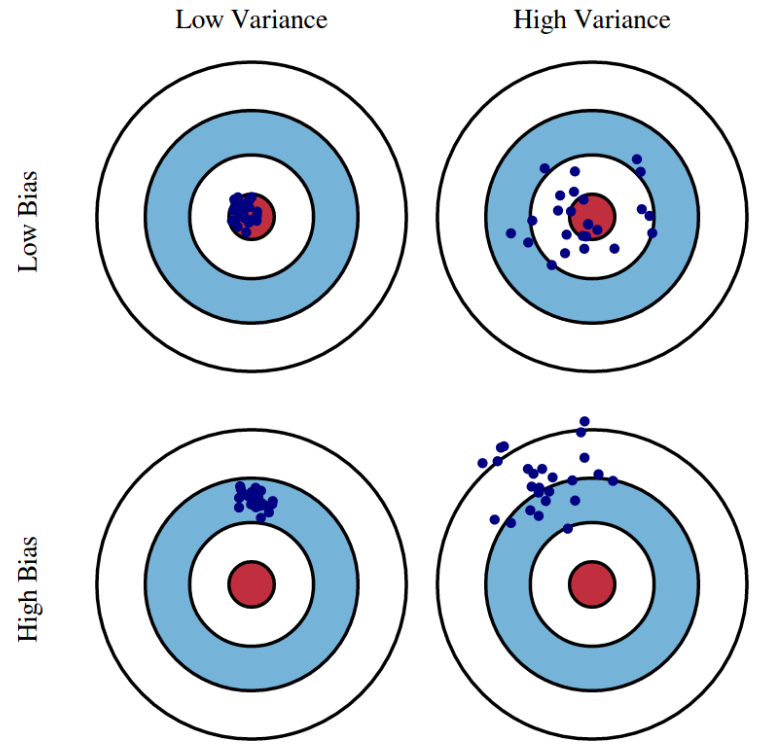

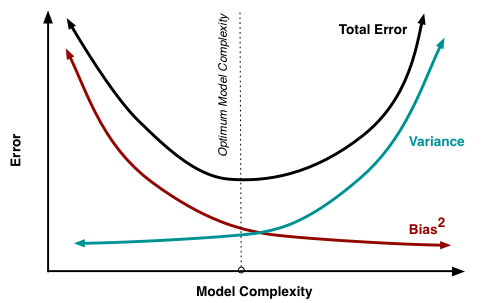

---

### Empirical risk

The core idea is based on an application of the law of large numbers; more specifically, we cannot know exactly how well a predictive algorithm will work in practice (i.e. the "true risk") because we do not know the true distribution of the data, but we can instead estimate and optimize the performance of the algorithm on a known set of training data. Since we do not know the true distribution $P$, we cannot compute $R(f)$. Instead, we approximate it using the training data, defining the empirical risk:

$$
\hat{R}(f) = \frac{1}{n} \sum_{i=1}^{n} L(f(x^{(i)}), y^{(i)})
$$

which corresponds to the training error so the performance over the known set of training data is referred to as the "empirical risk".

### ERM

This leads to the principle of Empirical Risk Minimization (ERM), where we choose $f$ that minimizes $\hat{R}(f)$:

$$
\min_f \hat{R}(f)
$$

The true risk represents error in the real world, while the empirical risk measures error on the training data. The objective is to minimize the former using the latter. Machine learning can be seen as minimizing a loss on observed data in the hope that this also minimizes real-world error. However, minimizing training error alone is not sufficient, since overfitting, data mismatch, or high variance may occur.

The training error is precisely the empirical risk, while dev/test error serves as an estimate of the true risk. The Bayes error is defined as:

$$
R^* = \min_f R(f)
$$

and represents the lowest achievable error. When minimizing empirical risk, failing to reduce it indicates high bias, while reducing it too well without generalization indicates high variance.

### Guarantees and Limitations of ERM

#### Guarantees

The performance guarantees of Empirical Risk Minimization (ERM) depend strongly on the chosen function (hypothesis) class and on the assumptions made on the data distribution Distribution-free bounds can be derived using the **VC (Vapnik–Chervonenkis) complexity** of the hypothesis class. For binary classification, the probability that the selected classifier $\phi_n$ is significantly worse than the optimal classifier $\phi^*$ can be bounded as:

$$
\mathbb{P}\left( L(\phi_n) - L(\phi^*) > \epsilon \right)
\;\leq\;
8 \, \mathcal{S}(\mathcal{C}, n)\, \exp\left(-\frac{n \epsilon^2}{32}\right)
$$

where:
- $L(\cdot)$ is the risk (expected loss)
- $\mathcal{S}(\mathcal{C}, n)$ is the **growth function** of the hypothesis class

#### No Free Lunch Theorem

When no assumptions are made about the data distribution, we obtain **impossibility results**, known as the *No Free Lunch* theorem. Even if a learning algorithm is asymptotically optimal for any distribution, its **finite-sample performance** must be poor for at least one distribution.

Specifically, for any classifier $\phi_n$ and any sample size $n$, for every $\epsilon > 0$, there exists a distribution with **Bayes error** $L^* = 0$ such that:

$$
\mathbb{E}[L_n] \;\geq\; \frac{1}{2} - \epsilon
$$

This implies:
> No classifier can universally achieve low error across all possible distributions at a fixed sample size.

#### Computational Complexity

ERM with **0-1 loss** is computationally intractable. It is **NP-hard**, even for simple hypothesis classes such as linear classifiers.

Practical solutions deal with use a **convex surrogate loss**. Example: hinge loss (used in SVMs)

#### Convexification and Zhang's Lemma

In the convex setting, **Zhang's lemma** provides a key guarantee:

- It bounds the **excess risk** of the original (0-1 loss) problem
- using the **excess risk** of the convex surrogate problem

Therefore:

> Minimizing the convex surrogate risk also controls the original classification risk.

### Bayes, likelihood and cross-entropy

The Bayes Decision Rule describes the optimal predictor. In classification:

$$
f^*(x) = \arg\max_y P(y \mid x)
$$

This rule selects the most probable class given $x$, achieving the Bayes error.

Since this involves $P(y|x)$, machine learning models can be interpreted as probability estimators. Because the true distribution is unknown, we approximate it with a parametric model $P_\theta(y|x)$. We want this probability to be high for the observed data, so we maximize the likelihood:

$$
\prod_{i=1}^{n} P_\theta(y^{(i)} \mid x^{(i)})
$$

Taking the logarithm simplifies computation, giving the log-likelihood:

$$
\sum_{i=1}^{n} \log P_\theta(y^{(i)} \mid x^{(i)})
$$

Maximizing this is equivalent to minimizing the cross-entropy loss:

$$
\text{Loss} = -\frac{1}{n} \sum_{i=1}^{n} \log P_\theta(y^{(i)} \mid x^{(i)})
$$

which in turn corresponds to minimizing the empirical risk.

Cross-entropy is particularly important because it theoretically leads toward the Bayes decision rule. If the model is perfect:

$$
P_\theta(y|x) \to P(y|x)
$$

and thus achieves optimal decisions and the Bayes error. Cross-entropy penalizes assigning low probability to the correct class, forcing the model to approximate the true distribution.

If cross-entropy cannot be minimized, the model has high bias; if it is minimized but generalization is poor, variance is high. Deep learning works because it minimizes cross-entropy, which is equivalent to maximizing log-likelihood, which estimates $P(y|x)$, approximates the Bayes decision rule, and ultimately minimizes the true risk.

### KL divergence

To deepen this perspective, we introduce the KL divergence, which measures how different two distributions are:

$$
D_{KL}(P \parallel Q) = \sum_y P(y) \log \frac{P(y)}{Q(y)}
$$

(This is the discrete-variable formula. For continuous variables, replace the sum with an integral.)

In our setting, $P(y|x)$ is the true distribution and $Q(y|x) = P_\theta(y|x)$ is the model. The real objective is:

$$
\min D_{KL}(P(y|x) \parallel P_\theta(y|x))
$$

which means making the model as close as possible to reality. A key identity shows that:

$$
D_{KL}(P \parallel Q) = H(P, Q) - H(P)
$$

where $H(P, Q)$ is the cross-entropy and $H(P)$ is the true entropy. Since $H(P)$ does not depend on the model, minimizing KL divergence is equivalent to minimizing cross-entropy. In practice, minimizing cross-entropy is therefore equivalent to minimizing KL divergence and learning the true distribution. Since:

$$
\text{Cross-Entropy} = -\mathbb{E}[\log P_\theta(y|x)]
$$

minimizing it corresponds to maximizing log-likelihood and minimizing KL divergence. Training a neural network can thus be interpreted as reducing the discrepancy between what the world does and what the model believes. We do not minimize KL divergence directly because the true distribution $P(y|x)$ is unknown; instead, we rely on empirical samples $(x,y)$, leading naturally to cross-entropy.

In summary, deep learning trains models by minimizing cross-entropy, which is equivalent to minimizing the KL divergence between the true distribution and the model, thereby approximating the Bayes decision rule.

---

<a id="evaluation-protocol"></a>
## Evaluation Protocol

Proper evaluation requires held-out data the model has never seen. Core principle: **never use test data to make modeling decisions**.

### Train / Validation / Test Split

| Split | Purpose | Typical size |
|-------|---------|:------------:|
| **Train** | Fit model parameters | 60–80 % |
| **Validation** | Tune hyperparameters, model selection | 10–20 % |
| **Test** | Final unbiased estimate of generalization | 10–20 % |

Using the test set for model selection introduces **optimistic bias** — test error underestimates the true risk.

### K-Fold Cross-Validation

When data is limited, k-fold CV provides a lower-variance estimate of generalization by using every sample for both training and evaluation:

1. Partition $\mathcal{D}$ into $k$ equal folds $F_1, \ldots, F_k$
2. For $i = 1, \ldots, k$: train on $\mathcal{D} \setminus F_i$, evaluate on $F_i$
3. Report mean ± std of the $k$ scores

$$\widehat{\text{CV}}(h) = \frac{1}{k} \sum_{i=1}^{k} \hat{R}_{F_i}(h)$$

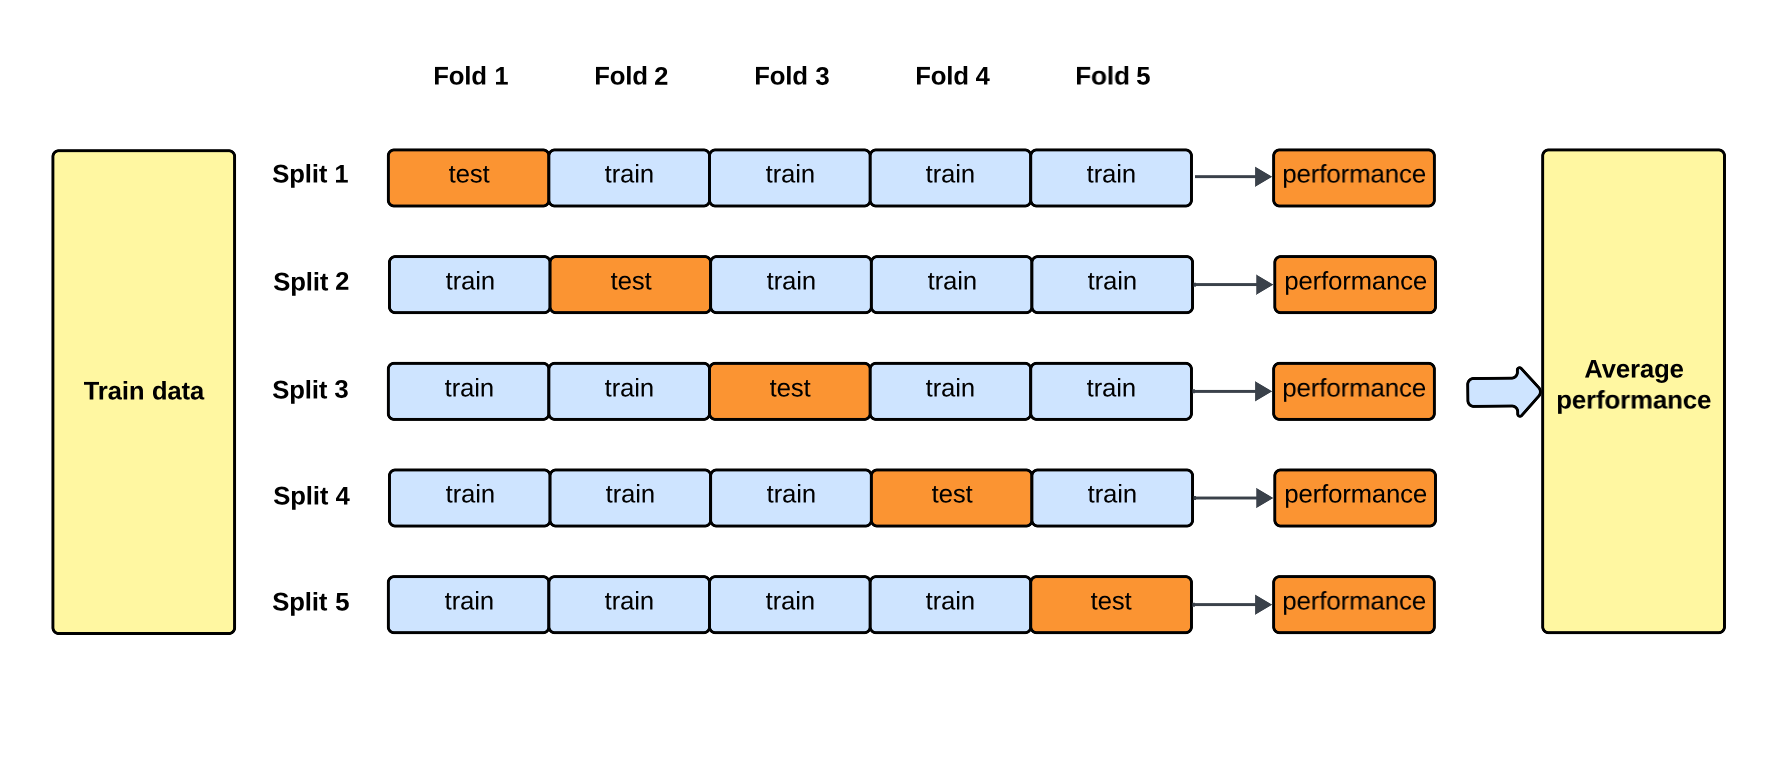

**Stratified k-fold**: preserves class proportions in each fold — essential for imbalanced datasets.  
**Leave-One-Out (LOO)**: $k = n$, nearly unbiased but $O(n)$ model fits.

| Method | Bias | Variance | Cost |
|--------|:----:|:--------:|:----:|
| Single holdout | Higher | Lower | 1× |
| 5-fold CV | Lower | Moderate | 5× |
| 10-fold CV | Lower | Lower | 10× |
| LOO | Very low | High | $n$× |

In [2]:
import numpy as np
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score as sklearn_cv

# --- Train / Val / Test split ---

def train_val_test_split(X, y, val_size=0.15, test_size=0.15, random_state=42):
    rng = np.random.RandomState(random_state)
    n = len(X)
    idx = rng.permutation(n)
    n_test = int(n * test_size)
    n_val  = int(n * val_size)
    test_idx  = idx[:n_test]
    val_idx   = idx[n_test:n_test + n_val]
    train_idx = idx[n_test + n_val:]
    return (X[train_idx], X[val_idx], X[test_idx],
            y[train_idx], y[val_idx], y[test_idx])

X, y = load_breast_cancer(return_X_y=True)
X_train, X_val, X_test, y_train, y_val, y_test = train_val_test_split(X, y)
print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print(f"Class balance — train: {y_train.mean():.2f}  val: {y_val.mean():.2f}  test: {y_test.mean():.2f}")

# --- Stratified K-Fold cross-validation ---

def kfold_split(n, k, stratify=None, random_state=42):
    """Yield (train_idx, val_idx) for each of k folds."""
    rng = np.random.RandomState(random_state)
    if stratify is None:
        idx = rng.permutation(n)
        folds = np.array_split(idx, k)
    else:
        classes = np.unique(stratify)
        class_folds = [np.array_split(rng.permutation(np.where(stratify == c)[0]), k)
                       for c in classes]
        folds = [np.concatenate([cf[i] for cf in class_folds]) for i in range(k)]
    for i in range(k):
        val_idx   = folds[i]
        train_idx = np.concatenate([folds[j] for j in range(k) if j != i])
        yield train_idx.astype(int), val_idx.astype(int)

def cross_val_score(estimator, X, y, k=5, random_state=42):
    scores = []
    for train_idx, val_idx in kfold_split(len(X), k, stratify=y, random_state=random_state):
        estimator.fit(X[train_idx], y[train_idx])
        acc = (estimator.predict(X[val_idx]) == y[val_idx]).mean()
        scores.append(acc)
    return np.array(scores)

X, y = load_iris(return_X_y=True)
clf = KNeighborsClassifier(n_neighbors=5)
scores_custom  = cross_val_score(clf, X, y, k=5)
scores_sklearn = sklearn_cv(clf, X, y, cv=5, scoring='accuracy')
print(f"\nCustom  5-fold CV: {scores_custom.mean():.4f} ± {scores_custom.std():.4f}")
print(f"Sklearn 5-fold CV: {scores_sklearn.mean():.4f} ± {scores_sklearn.std():.4f}")

Train: 399 | Val: 85 | Test: 85
Class balance — train: 0.63  val: 0.62  test: 0.64

Custom  5-fold CV: 0.9667 ± 0.0211
Sklearn 5-fold CV: 0.9733 ± 0.0249


---

<a id="classification-metrics"></a>
## Evaluation Metrics — Classification

Given predictions $\hat{y}_i$ and true labels $y_i$, the **confusion matrix** aggregates outcomes into four categories:

|  | Predicted Positive | Predicted Negative |
|--|:-----------------:|:-----------------:|
| **Actual Positive** | TP | FN |
| **Actual Negative** | FP | TN |

**Accuracy**:
$$\text{Acc} = \frac{TP + TN}{TP + TN + FP + FN}$$

**Precision** — of all positive predictions, how many were correct:
$$\text{Prec} = \frac{TP}{TP + FP}$$

**Recall / Sensitivity** — of all actual positives, how many were found:
$$\text{Rec} = \frac{TP}{TP + FN}$$

**F1 Score** — harmonic mean of precision and recall:
$$F_1 = \frac{2 \cdot \text{Prec} \cdot \text{Rec}}{\text{Prec} + \text{Rec}} = \frac{2\,TP}{2\,TP + FP + FN}$$

**ROC-AUC** — area under the TPR vs FPR curve, threshold-independent:
$$TPR = \frac{TP}{TP + FN}, \quad FPR = \frac{FP}{FP + TN}$$

AUC = 0.5 → random classifier; AUC = 1.0 → perfect.

**Multiclass averaging**:
- *Macro*: unweighted mean over classes
- *Weighted*: weighted by class frequency

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score)

# --- From-scratch implementations ---

def confusion_matrix_scratch(y_true, y_pred, n_classes=2):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm

def accuracy(y_true, y_pred):
    return (y_true == y_pred).mean()

def precision_recall_f1(y_true, y_pred, pos=1):
    tp = ((y_true == pos) & (y_pred == pos)).sum()
    fp = ((y_true != pos) & (y_pred == pos)).sum()
    fn = ((y_true == pos) & (y_pred != pos)).sum()
    prec = tp / (tp + fp + 1e-15)
    rec  = tp / (tp + fn + 1e-15)
    f1   = 2 * prec * rec / (prec + rec + 1e-15)
    return float(prec), float(rec), float(f1)

def roc_curve_scratch(y_true, y_score):
    thresholds = np.sort(np.unique(y_score))[::-1]
    pos = (y_true == 1).sum()
    neg = (y_true == 0).sum()
    tprs, fprs = [0.], [0.]
    for t in thresholds:
        y_pred = (y_score >= t).astype(int)
        tp = ((y_true == 1) & (y_pred == 1)).sum()
        fp = ((y_true == 0) & (y_pred == 1)).sum()
        tprs.append(tp / pos); fprs.append(fp / neg)
    tprs.append(1.); fprs.append(1.)
    return np.array(fprs), np.array(tprs)

def auc_trapz(fpr, tpr):
    return float(np.trapezoid(tpr, fpr))

# --- Demo on breast cancer dataset ---
X, y = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(
    StandardScaler().fit_transform(X), y, test_size=0.2, random_state=42, stratify=y)

clf = LogisticRegression(max_iter=1000).fit(X_tr, y_tr)
y_pred  = clf.predict(X_te)
y_score = clf.predict_proba(X_te)[:, 1]

prec, rec, f1 = precision_recall_f1(y_te, y_pred)
fpr, tpr      = roc_curve_scratch(y_te, y_score)
auc           = auc_trapz(fpr, tpr)

print("             Custom   |  sklearn")
print(f"  Accuracy : {accuracy(y_te, y_pred):.4f}  |  {accuracy_score(y_te, y_pred):.4f}")
print(f"  Precision: {prec:.4f}  |  {precision_score(y_te, y_pred):.4f}")
print(f"  Recall   : {rec:.4f}  |  {recall_score(y_te, y_pred):.4f}")
print(f"  F1       : {f1:.4f}  |  {f1_score(y_te, y_pred):.4f}")
print(f"  ROC-AUC  : {auc:.4f}  |  {roc_auc_score(y_te, y_score):.4f}")

# --- Plots ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm = confusion_matrix_scratch(y_te, y_pred)
im = axes[0].imshow(cm, cmap='Blues')
axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(['Pred 0', 'Pred 1']); axes[0].set_yticklabels(['True 0', 'True 1'])
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha='center', va='center', fontsize=14,
                     color='white' if cm[i, j] > cm.max() / 2 else 'black')
axes[0].set_title("Confusion Matrix"); plt.colorbar(im, ax=axes[0])

axes[1].plot(fpr, tpr, lw=2, label=f"ROC (AUC = {auc:.3f})")
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel("FPR"); axes[1].set_ylabel("TPR"); axes[1].set_title("ROC Curve"); axes[1].legend()

plt.tight_layout(); plt.show()

---

<a id="regression-metrics"></a>
## Evaluation Metrics — Regression

**Mean Squared Error (MSE)** — penalizes large errors quadratically:
$$MSE = \frac{1}{n} \sum_{i=1}^n (\hat{y}_i - y_i)^2$$

**Root MSE (RMSE)** — same units as $y$:
$$RMSE = \sqrt{MSE}$$

**Mean Absolute Error (MAE)** — linear penalty, robust to outliers:
$$MAE = \frac{1}{n} \sum_{i=1}^n |\hat{y}_i - y_i|$$

**R² Score (Coefficient of Determination)** — fraction of variance explained:
$$R^2 = 1 - \frac{\sum_i (\hat{y}_i - y_i)^2}{\sum_i (\bar{y} - y_i)^2} \in (-\infty, 1]$$

$R^2 = 1$: perfect. $R^2 = 0$: predicts mean. $R^2 < 0$: worse than predicting the mean.

**Mean Absolute Percentage Error (MAPE)**:
$$MAPE = \frac{100}{n} \sum_{i=1}^n \left|\frac{\hat{y}_i - y_i}{y_i}\right|$$

> MSE and RMSE are the most common in practice. Use MAE when outliers should not dominate. Use R² to communicate "how much variance is explained" to non-technical audiences.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# --- From-scratch implementations ---

def mse(y_true, y_pred):
    return float(np.mean((y_true - y_pred) ** 2))

def rmse(y_true, y_pred):
    return float(np.sqrt(mse(y_true, y_pred)))

def mae(y_true, y_pred):
    return float(np.mean(np.abs(y_true - y_pred)))

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return float(1 - ss_res / ss_tot)

def mape(y_true, y_pred):
    return float(100 * np.mean(np.abs((y_true - y_pred) / (np.abs(y_true) + 1e-15))))

# --- Demo on California Housing ---
X, y = fetch_california_housing(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
reg = LinearRegression().fit(scaler.fit_transform(X_tr), y_tr)
y_pred = reg.predict(scaler.transform(X_te))

print("             Custom   |  sklearn")
print(f"  MSE  : {mse(y_te, y_pred):.4f}  |  {mean_squared_error(y_te, y_pred):.4f}")
print(f"  RMSE : {rmse(y_te, y_pred):.4f}")
print(f"  MAE  : {mae(y_te, y_pred):.4f}  |  {mean_absolute_error(y_te, y_pred):.4f}")
print(f"  R²   : {r2(y_te, y_pred):.4f}  |  {r2_score(y_te, y_pred):.4f}")
print(f"  MAPE : {mape(y_te, y_pred):.2f}%")

# --- Plots ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_te, y_pred, alpha=0.3, s=8)
lims = [min(y_te.min(), y_pred.min()), max(y_te.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', lw=1.5)
axes[0].set_xlabel("True values"); axes[0].set_ylabel("Predicted")
axes[0].set_title(f"Actual vs Predicted  (R² = {r2(y_te, y_pred):.3f})")

residuals = y_te - y_pred
axes[1].hist(residuals, bins=60, edgecolor='k', alpha=0.7)
axes[1].axvline(0, color='r', lw=1.5, ls='--')
axes[1].set_xlabel("Residual"); axes[1].set_ylabel("Count"); axes[1].set_title("Residual Distribution")

plt.tight_layout(); plt.show()

---

<a id="feature-scaling"></a>
## Feature Scaling

Many algorithms (KNN, SVM, gradient descent, PCA) are sensitive to feature magnitude. Without scaling, features with larger ranges dominate distance computations and gradient updates.

### Standardization (Z-score normalization)

Maps each feature to zero mean and unit variance:
$$x' = \frac{x - \mu}{\sigma}$$

Preserves the shape of the distribution. Sensitive to outliers. Required for PCA and distance-based methods.

### Min-Max Normalization

Scales each feature to $[0, 1]$:
$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

Bounded range. Very sensitive to outliers since $x_{\min}$ and $x_{\max}$ shift with a single extreme value.

### Robust Scaling

Uses median and interquartile range (IQR) — outlier-resistant:
$$x' = \frac{x - \text{median}(x)}{IQR(x)}, \quad IQR = Q_{75} - Q_{25}$$

**Critical rule**: always `fit` the scaler on training data only, then `transform` val/test separately.  
Fitting on the full dataset leaks test statistics into training → optimistically biased results.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler as SkStd, MinMaxScaler as SkMM

class StandardScalerScratch:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_  = X.std(axis=0)
        return self
    def transform(self, X):
        return (X - self.mean_) / (self.std_ + 1e-15)
    def fit_transform(self, X):
        return self.fit(X).transform(X)
    def inverse_transform(self, X):
        return X * self.std_ + self.mean_

class MinMaxScalerScratch:
    def __init__(self, feature_range=(0, 1)):
        self.a, self.b = feature_range
    def fit(self, X):
        self.min_ = X.min(axis=0)
        self.max_ = X.max(axis=0)
        return self
    def transform(self, X):
        x_std = (X - self.min_) / (self.max_ - self.min_ + 1e-15)
        return x_std * (self.b - self.a) + self.a
    def fit_transform(self, X):
        return self.fit(X).transform(X)

class RobustScalerScratch:
    def fit(self, X):
        self.median_ = np.median(X, axis=0)
        self.iqr_    = np.percentile(X, 75, axis=0) - np.percentile(X, 25, axis=0)
        return self
    def transform(self, X):
        return (X - self.median_) / (self.iqr_ + 1e-15)
    def fit_transform(self, X):
        return self.fit(X).transform(X)

# --- Demo: 2D data with one outlier ---
rng = np.random.RandomState(42)
X_raw = rng.randn(100, 2) * np.array([1.0, 100.0])
X_raw[0] = [10.0, 10_000.0]  # outlier

std_out = StandardScalerScratch().fit_transform(X_raw)
mm_out  = MinMaxScalerScratch().fit_transform(X_raw)
rob_out = RobustScalerScratch().fit_transform(X_raw)

print("Max abs diff vs sklearn:")
print(f"  StandardScaler: {np.abs(std_out - SkStd().fit_transform(X_raw)).max():.2e}")
print(f"  MinMaxScaler  : {np.abs(mm_out  - SkMM().fit_transform(X_raw)).max():.2e}")

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, d, t in zip(axes,
                    [X_raw, std_out, mm_out, rob_out],
                    ["Raw", "Standard", "MinMax", "Robust"]):
    ax.scatter(d[:, 0], d[:, 1], alpha=0.5, s=15)
    ax.set_title(t); ax.set_xlabel("Feature 1"); ax.set_ylabel("Feature 2")
plt.tight_layout(); plt.show()

---

<a id="practical-pipeline"></a>
## Practical Pipeline

A sklearn `Pipeline` chains preprocessing and modelling steps into a single object. This ensures the scaler is fit only on training data in each CV fold — no leakage possible.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.datasets import load_breast_cancer

X, y = load_breast_cancer(return_X_y=True)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    LogisticRegression(max_iter=1000)),
])

# 10-fold CV — scaler is re-fit on each training fold, not on val fold
scores = cross_val_score(pipe, X, y, cv=10, scoring='accuracy')
print(f"10-fold CV accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

# Grid search over pipeline hyperparameters using double-underscore notation
param_grid = {'clf__C': [0.01, 0.1, 1.0, 10.0, 100.0]}
gs = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
gs.fit(X, y)
print(f"Best C    : {gs.best_params_['clf__C']}")
print(f"Best score: {gs.best_score_:.4f}")

---

<a id="sources"></a>
## Sources

1. Shalev-Shwartz, S. & Ben-David, S. (2014). *Understanding Machine Learning: From Theory to Algorithms*. Cambridge University Press.
2. Hastie, T., Tibshirani, R. & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer. [ESL]
3. Murphy, K.P. (2012). *Machine Learning: A Probabilistic Perspective*. MIT Press.
4. Bishop, C.M. (2006). *Pattern Recognition and Machine Learning*. Springer.
5. Vapnik, V.N. (1998). *Statistical Learning Theory*. Wiley.
6. Wolpert, D.H. (1996). The Lack of A Priori Distinctions Between Learning Algorithms. *Neural Computation*, 8(7), 1341–1390. [No Free Lunch]
7. Zhang, T. (2004). Statistical Analysis of Some Multi-Category Large Margin Classification Methods. *JMLR*, 5, 1225–1251. [Zhang's Lemma]
8. scikit-learn documentation — https://scikit-learn.org